# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: C:\Users\sarao\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt


torch.manual_seed(42)

## Step 2 — Upload the dataset

In [7]:

df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())

display(df.head())



Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


In [4]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\sarao\NLP_Lab11
['.git', '.ipynb_checkpoints', 'dataset', 'Lab_11_Attention_with_RNN.ipynb']


In [5]:
import os

print(os.listdir("dataset"))

['.ipynb_checkpoints', 'Lab_11_QnA_Dataset.csv']


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [8]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [9]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [10]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

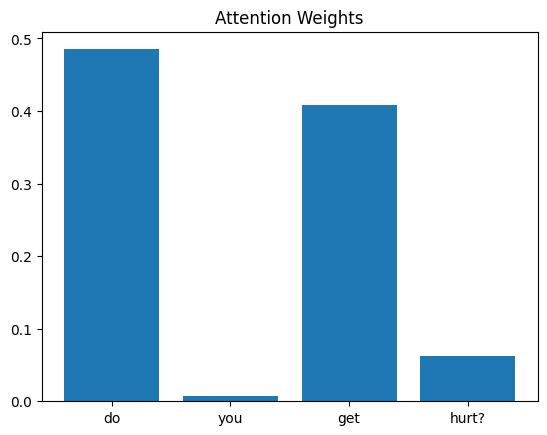

In [11]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Highest attention: do (0.4851)


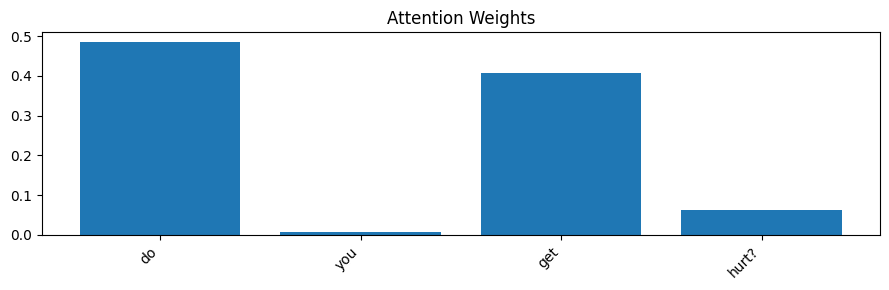

Question: who is your momma?
Highest attention: is (0.4881)


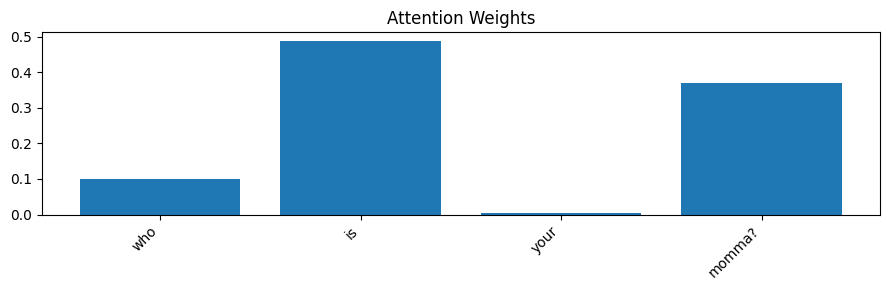

Question: that was a pretty genius answer
Highest attention: that (0.2560)


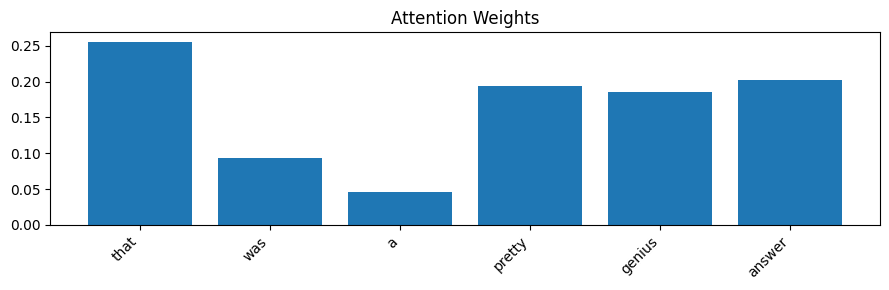

Observation: The highest-weight words are often content words that help distinguish the question, such as key nouns or verbs. This is not guaranteed for every question, and attention weights alone do not prove that a word caused the prediction.


In [12]:
selected_indices = [0, len(df) // 2, len(df) - 1]

model.eval()

for index in selected_indices:
    question = df["question"].iloc[index]
    words = question.split()
    sequence = torch.tensor(
        pad_sequences(tokenizer.texts_to_sequences([question]), maxlen=X.shape[1], padding="post"),
        dtype=torch.long
    )

    with torch.no_grad():
        prediction, weights = model(sequence)

    word_weights = weights[0, :len(words)].tolist()
    highest_index = max(range(len(word_weights)), key=lambda i: word_weights[i])

    print("Question:", question)
    print("Highest attention:", words[highest_index], f"({word_weights[highest_index]:.4f})")
    plt.figure(figsize=(9, 3))
    plt.bar(words, word_weights)
    plt.title("Attention Weights")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

print("Observation: The highest-weight words are often content words that help distinguish the question, such as key nouns or verbs. This is not guaranteed for every question, and attention weights alone do not prove that a word caused the prediction.")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

In [14]:
print(df.columns)
print(df["answer_id"].unique())

Index(['question', 'answer_id', 'answer'], dtype='str')
[ 0  1  2  3  4  5  6  7  8  9 10 11]


In [16]:
answer_labels = sorted(df["answer_id"].unique())

Question: what kind of responses can you give ?
Predicted answer_id: 0
Highest attention: responses (0.4739)


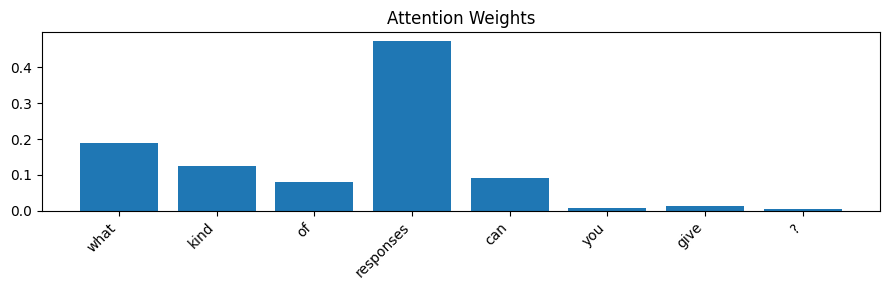

Question: what kind of thing can you respond to?
Predicted answer_id: 10
Highest attention: to? (0.9546)


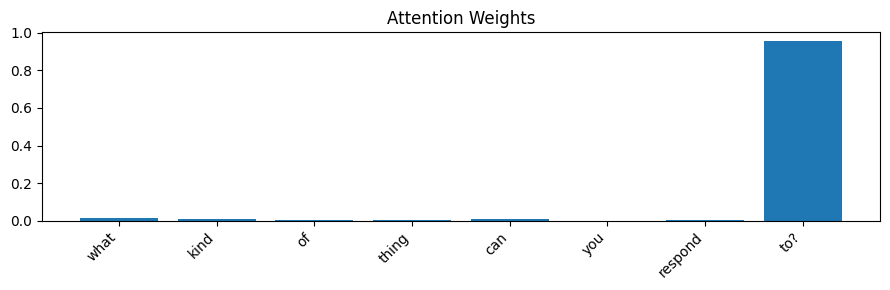

Observation: Questions with the same answer_id may receive attention on overlapping keywords, but the model can also focus on different words because their wording differs. Attention shows the model's learned weighting, not a guaranteed explanation of its decision.


In [17]:
from itertools import combinations

question_rows = df[["question", "answer_id"]].dropna().reset_index(drop=True)
candidate_pairs = []

for (i, row_a), (j, row_b) in combinations(question_rows.iterrows(), 2):
    question_a = row_a["question"].strip()
    question_b = row_b["question"].strip()

    if row_a["answer_id"] != row_b["answer_id"] or question_a == question_b:
        continue

    words_a = set(question_a.split())
    words_b = set(question_b.split())
    union = words_a | words_b

    if not union:
        continue

    similarity = len(words_a & words_b) / len(union)
    candidate_pairs.append((similarity, i, j))

if not candidate_pairs:
    raise ValueError("No two different questions with the same answer_id were found in the dataset.")

candidate_pairs.sort(key=lambda item: (item[0] >= 0.95, abs(item[0] - 0.45)))
similarity, index_a, index_b = candidate_pairs[0]

questions = [
    question_rows.loc[index_a, "question"],
    question_rows.loc[index_b, "question"]
]

model.eval()

for question in questions:
    words = question.split()
    sequence = torch.tensor(
        pad_sequences(tokenizer.texts_to_sequences([question]), maxlen=X.shape[1], padding="post"),
        dtype=torch.long
    )

    with torch.no_grad():
        logits, weights = model(sequence)
        predicted_answer = answer_labels[int(logits.argmax(dim=1).item())]

    word_weights = weights[0, :len(words)].tolist()
    highest_index = max(range(len(word_weights)), key=lambda i: word_weights[i])

    print("Question:", question)
    print("Predicted answer_id:", predicted_answer)
    print("Highest attention:", words[highest_index], f"({word_weights[highest_index]:.4f})")

    plt.figure(figsize=(9, 3))
    plt.bar(words, word_weights)
    plt.title("Attention Weights")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

print("Observation: Questions with the same answer_id may receive attention on overlapping keywords, but the model can also focus on different words because their wording differs. Attention shows the model's learned weighting, not a guaranteed explanation of its decision.")